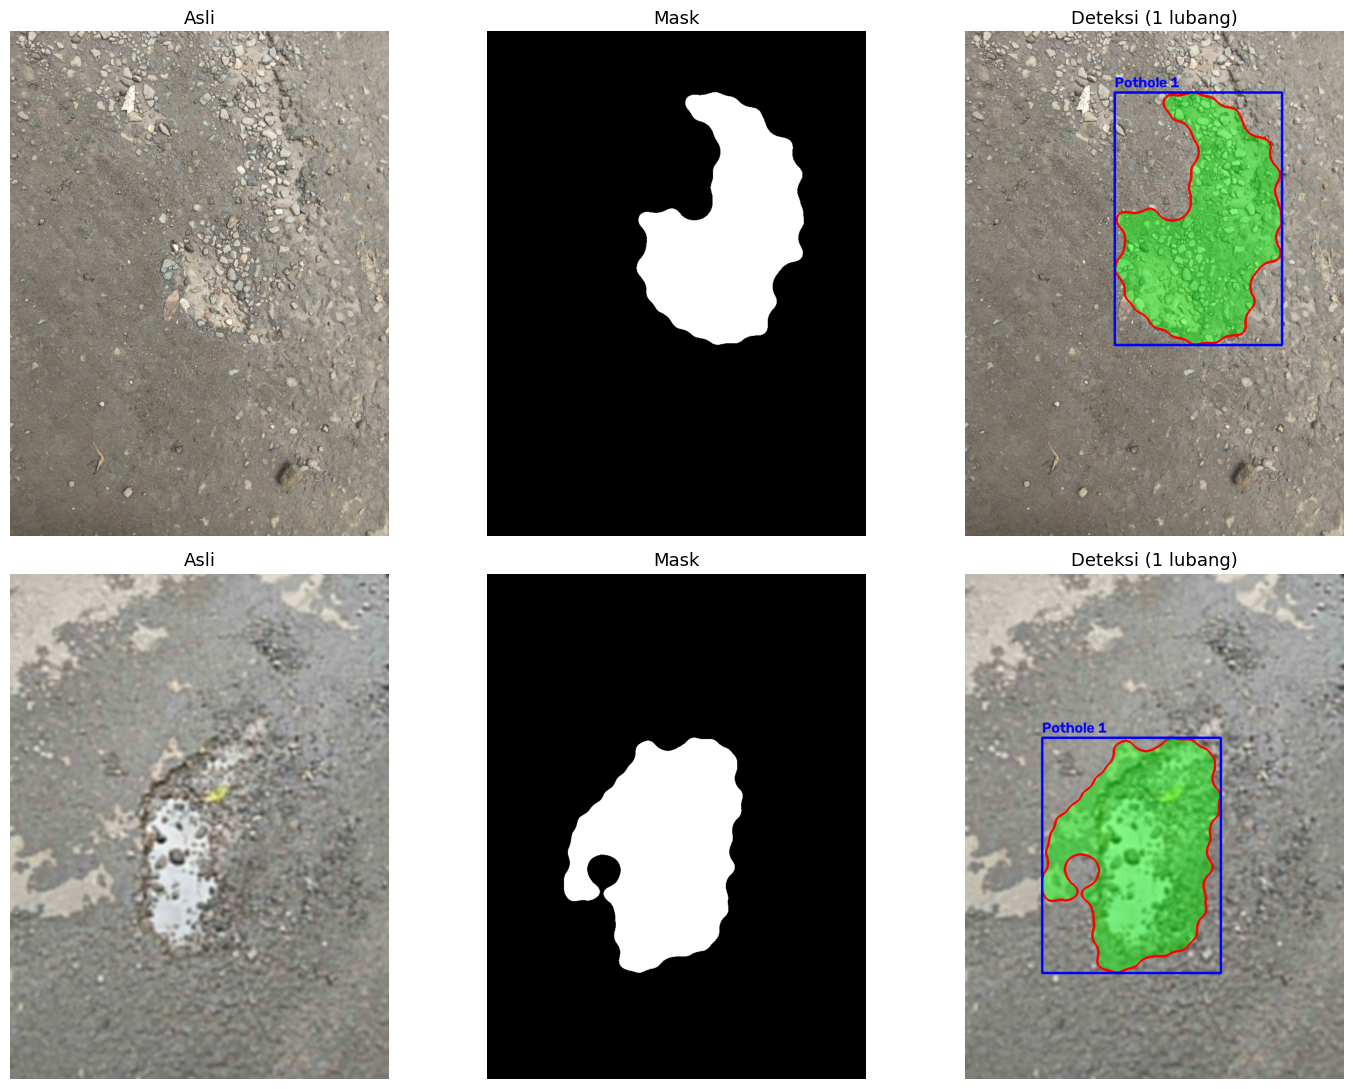

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def fill_and_smooth_mask(binary_mask, blur_ksize=31):
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    solid_mask = np.zeros_like(binary_mask)
    if not contours:
        return solid_mask
    cnt = max(contours, key=cv2.contourArea)
    cv2.drawContours(solid_mask, [cnt], -1, 255, thickness=cv2.FILLED)

    smoothed = cv2.GaussianBlur(solid_mask, (blur_ksize, blur_ksize), 0)
    _, smoothed = cv2.threshold(smoothed, 127, 255, cv2.THRESH_BINARY)

    contours2, _ = cv2.findContours(smoothed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    final_mask = np.zeros_like(binary_mask)
    if contours2:
        cnt2 = max(contours2, key=cv2.contourArea)
        cv2.drawContours(final_mask, [cnt2], -1, 255, thickness=cv2.FILLED)
    return final_mask

def detect_pothole_gravel(img_bgr):
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    blur_small = cv2.GaussianBlur(gray, (5, 5), 0)
    blur_large = cv2.GaussianBlur(gray, (25, 25), 0)
    high_pass = cv2.absdiff(blur_small, blur_large)
    texture_map = cv2.GaussianBlur(high_pass, (35, 35), 0)

    roi_weight = np.zeros((h, w), dtype=np.float32)
    cv2.ellipse(roi_weight, (int(w * 0.62), int(h * 0.42)), (int(w * 0.30), int(h * 0.32)), -15, 0, 360, 1.0, -1)
    roi_weight = cv2.GaussianBlur(roi_weight, (101, 101), 0)

    weighted_score = texture_map.astype(np.float32) * roi_weight
    _, thresh = cv2.threshold(weighted_score.astype(np.uint8), 11, 255, cv2.THRESH_BINARY)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (35, 35))
    mask = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    return fill_and_smooth_mask(mask, blur_ksize=31)

def detect_pothole_puddle(img_bgr):
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (15, 15), 0)

    roi_weight = np.zeros((h, w), dtype=np.float32)
    cv2.ellipse(roi_weight, (int(w * 0.46), int(h * 0.56)), (int(w * 0.24), int(h * 0.26)), 20, 0, 360, 1.0, -1)
    roi_weight = cv2.GaussianBlur(roi_weight, (81, 81), 0)

    bright_puddle = (blur > 165).astype(np.float32)
    dark_rim = (blur < 115).astype(np.float32)
    combined = np.clip((bright_puddle * 1.0 + dark_rim * 0.75) * roi_weight * 255, 0, 255).astype(np.uint8)

    _, thresh = cv2.threshold(combined, 110, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
    mask = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    return fill_and_smooth_mask(mask, blur_ksize=29)

def render_detection(img_rgb, mask):
    vis = img_rgb.copy()
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        cnt = max(contours, key=cv2.contourArea)
        # Overlay hijau semi-transparan
        overlay = vis.copy()
        cv2.drawContours(overlay, [cnt], -1, (0, 255, 0), thickness=cv2.FILLED)
        vis = cv2.addWeighted(overlay, 0.45, vis, 0.55, 0)

        # Garis tepi merah
        cv2.drawContours(vis, [cnt], -1, (255, 0, 0), thickness=3)

        # Bounding box biru & label biru "Pothole 1"
        x, y, bw, bh = cv2.boundingRect(cnt)
        cv2.rectangle(vis, (x, y), (x + bw, y + bh), (0, 0, 255), thickness=3)
        cv2.putText(
            vis, "Pothole 1", (x, max(y - 10, 30)),
            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), thickness=3, lineType=cv2.LINE_AA
        )
    return vis

# Muat kedua foto lubang jalan (menggunakan nama file yang benar)
img1_bgr = cv2.imread("lubang_1.jpg")
img2_bgr = cv2.imread("lubang_2.jpg")

img1_rgb = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2RGB)

# Masking & Deteksi Segmentasi
mask1 = detect_pothole_gravel(img1_bgr)
mask2 = detect_pothole_puddle(img2_bgr)

det1 = render_detection(img1_rgb, mask1)
det2 = render_detection(img2_rgb, mask2)

# Tampilkan hasil 2 baris x 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(15, 11))
rows = [(img1_rgb, mask1, det1), (img2_rgb, mask2, det2)]

for r_idx, (asli, msk, det) in enumerate(rows):
    axes[r_idx, 0].imshow(asli)
    axes[r_idx, 0].set_title("Asli", fontsize=13)
    axes[r_idx, 0].axis("off")

    axes[r_idx, 1].imshow(msk, cmap="gray", vmin=0, vmax=255)
    axes[r_idx, 1].set_title("Mask", fontsize=13)
    axes[r_idx, 1].axis("off")

    axes[r_idx, 2].imshow(det)
    axes[r_idx, 2].set_title("Deteksi (1 lubang)", fontsize=13)
    axes[r_idx, 2].axis("off")

plt.tight_layout()
plt.savefig("hasil_deteksi_lubang.png", dpi=200, bbox_inches="tight")
plt.show()